# 03 · Deconditioning: is fitness slipping?

The team's idea: in microgravity the heart and muscles decondition, so **the same exercise costs more heartbeats week after week**.
Compare heart rate within the same exercise type from week to week.

**Questions**
1. How much exercise data is there per person, and is it enough? (It is sparse; the numbers are below.)
2. Which model sees a planted gradual rise of +1 to +3 bpm per week soonest, at an acceptable false trend-alarm rate?

**Candidates:** A weekly median HR per activity type + Theil–Sen slope · B efficiency index HR ÷ speed for runs ·
C linear mixed model (HR ~ week + duration + type, random effects per person) · D change-point detection (PELT) on weekly HR.

**Inputs:** `data/raw/pmdata/*/fitbit/exercise.json` (real sessions), `data/processed/pmdata_daily.parquet` (injury days).
**Outputs:** comparison table, figures `reports/figures/03_*.png`, the chosen parameters in `models/engine_config.json`.

**Protocol:** the shared one, on a weekly clock. False alarms = trend-alert episodes per person-month on the real sessions (6-week warm-up,
weeks with an injury report excluded). Detection = weeks until the first new alert after a rise is planted into the real sessions
(missed if not caught within 8 weeks). Target: at most 1 false alarm per person-month, as in notebook 02.

In [1]:
import sys
sys.path.insert(0, "../ml")
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sol_ml.nbutil import *
from sol_ml.data import pmdata
from sol_ml.detectors import deconditioning as dc
from sol_ml.detectors.evaluation import count_episodes

rng = setup()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore")
DEPS = ["detectors/deconditioning.py", "detectors/evaluation.py"]
TARGET_FA, WARMUP, HORIZON, RATES, N_SITES = 1.0, 6, 8, (1.0, 2.0, 3.0), 200
ORIGIN = pd.Timestamp("2019-10-28")          # a Monday before the first PMData day: one week clock for everyone

raw = pd.concat([pmdata.load_exercise(p).assign(person=p.name) for p in pmdata.participants()], ignore_index=True)
sessions = dc.add_week(raw[raw.avg_hr.notna() & (raw.duration_min >= 10)], ORIGIN)
print(len(raw), "sessions logged,", len(sessions), "with a heart rate and at least 10 minutes")
sessions.head(3)

2440 sessions logged, 2389 with a heart rate and at least 10 minutes


,start,activity,duration_min,avg_hr,distance,steps,date,person,week
0,2019-11-01 14:56:32,Walk,22.183333,94.0,NaN,1878.0,2019-11-01,p01,0
1,2019-11-01 19:03:11,Walk,36.700000,94.0,NaN,2786.0,2019-11-01,p01,0
2,2019-11-02 13:26:38,Walk,40.966667,98.0,NaN,3035.0,2019-11-02,p01,0


## 1. How much data is there?

In [2]:
cov = sessions.groupby("person").agg(sessions=("avg_hr", "size"), weeks_with_exercise=("week", "nunique"),
                                     activity_types=("activity", "nunique"))
cov["paced_sessions"] = sessions[sessions.activity.isin(dc.PACED) & (sessions.distance > 0)].groupby("person").size()
by_type = sessions.groupby(["person", "activity"]).week.nunique().unstack(fill_value=0)
cov["types_with_8+_weeks"] = (by_type >= 8).sum(axis=1)
cov["best_type"] = by_type.idxmax(axis=1) + " (" + by_type.max(axis=1).astype(str) + " wk)"
cov = cov.fillna(0).astype({"paced_sessions": int})
print("people with 8+ weeks of at least one activity type:", int((cov["types_with_8+_weeks"] > 0).sum()), "of", len(cov))
print("people with 20+ paced sessions (run or treadmill with distance):", int((cov.paced_sessions >= 20).sum()))
print("share of all sessions that are auto-detected walks: %.0f%%" % (100 * (sessions.activity == "Walk").mean()))
cov

people with 8+ weeks of at least one activity type: 16 of 16
people with 20+ paced sessions (run or treadmill with distance): 8
share of all sessions that are auto-detected walks: 57%


,sessions,weeks_with_exercise,activity_types,paced_sessions,types_with_8+_weeks,best_type
person,,,,,,
p01,188,23,4,23,4,Walk (23 wk)
p02,322,22,9,27,4,Walk (22 wk)
p03,57,16,2,3,1,Walk (16 wk)
p04,155,22,10,41,4,Walk (19 wk)
p05,143,21,6,7,2,Walk (21 wk)
p06,156,23,5,46,4,Run (14 wk)
p07,170,22,7,97,4,Treadmill (18 wk)
p08,244,21,9,126,4,Run (20 wk)
p09,54,18,3,2,1,Walk (18 wk)


median within-person, within-type SD of session HR: 9.4 bpm


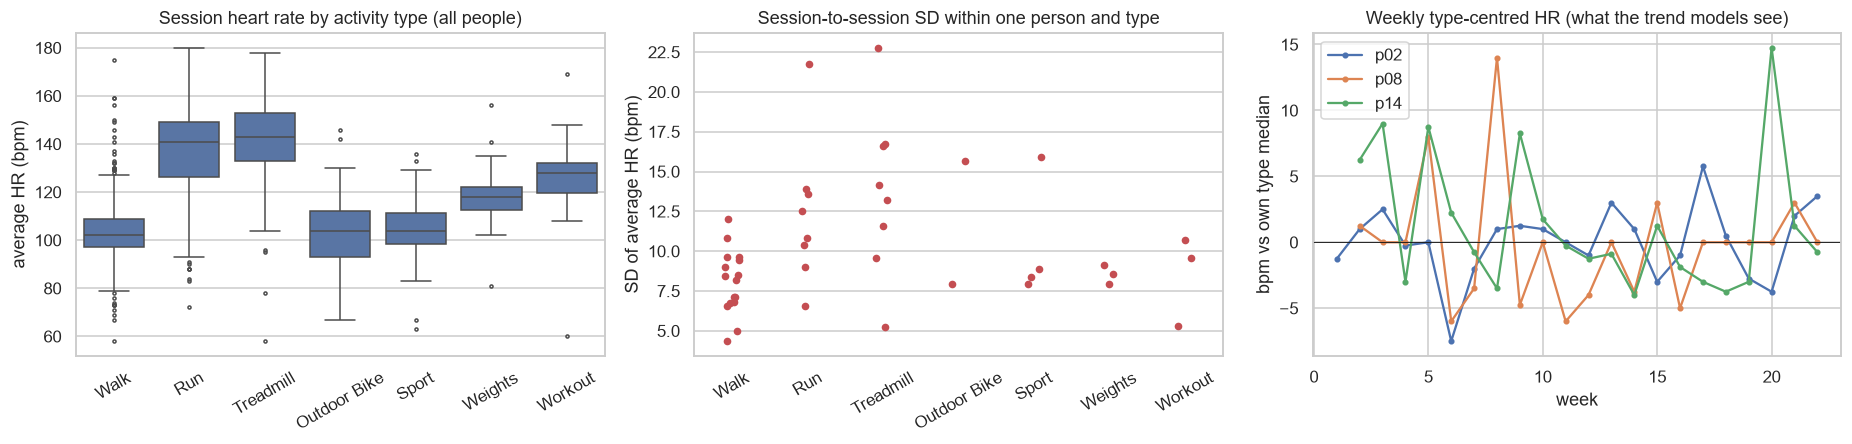

In [3]:
top = sessions.activity.value_counts().head(7).index
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.boxplot(data=sessions[sessions.activity.isin(top)], x="activity", y="avg_hr", order=top, ax=axes[0], color="#4c72b0", fliersize=2)
axes[0].set(title="Session heart rate by activity type (all people)", xlabel="", ylabel="average HR (bpm)")
axes[0].tick_params(axis="x", rotation=30)
within = sessions.groupby(["person", "activity"]).avg_hr.agg(["std", "size"]).query("size >= 10").reset_index()
sns.stripplot(data=within[within.activity.isin(top)], x="activity", y="std", order=top, ax=axes[1], color="#c44e52")
axes[1].set(title="Session-to-session SD within one person and type", xlabel="", ylabel="SD of average HR (bpm)")
axes[1].tick_params(axis="x", rotation=30)
for person in ["p02", "p08", "p14"]:
    g = sessions[(sessions.person == person)]
    wk, hr = dc.centered_weekly(g, 0, 99)
    axes[2].plot(*zip(*sorted(pd.Series(hr).groupby(wk).median().items())), marker="o", ms=3, label=person)
axes[2].axhline(0, color="k", lw=0.6)
axes[2].set(title="Weekly type-centred HR (what the trend models see)", xlabel="week", ylabel="bpm vs own type median")
axes[2].legend()
savefig("03_exercise_overview");
print("median within-person, within-type SD of session HR: %.1f bpm" % within["std"].median())

A planted rise of 1–3 bpm per week has to be seen against a session-to-session spread of several bpm, with only a few sessions per week and type.
That is the whole difficulty of this notebook.

## 2. Evaluation set-up

In [4]:
people = sorted(sessions.person.unique())
by_person = {p: g.reset_index(drop=True) for p, g in sessions.groupby("person")}
daily = pd.read_parquet(PROCESSED / "pmdata_daily.parquet")
injury_weeks = {p: set(((g.loc[g.injury, "date"] - ORIGIN).dt.days // 7).tolist()) for p, g in daily.groupby("person")}
WEEKS = np.arange(int(sessions.week.min()), int(sessions.week.max()) + 1)
first = {p: int(by_person[p].week.min()) for p in people}
mask = {p: np.array([(w >= first[p] + WARMUP) and (w <= by_person[p].week.max()) and (w not in injury_weeks.get(p, set()))
                     for w in WEEKS]) for p in people}
person_months = sum(m.sum() for m in mask.values()) * 7 / 30

valid = []
for p in people:
    g = by_person[p]
    for s in range(first[p] + WARMUP, int(g.week.max()) - HORIZON + 2):
        if g[(g.week >= s) & (g.week < s + HORIZON)].week.nunique() >= 5 and mask[p][(WEEKS >= s) & (WEEKS < s + HORIZON)].all():
            valid.append((p, s))
picks = rng.choice(len(valid), N_SITES, replace=len(valid) < N_SITES)
SITES = [valid[k] for k in picks]
print(f"{len(people)} people, {person_months:.0f} evaluated person-months, {len(valid)} possible (person, start week) pairs,",
      f"{N_SITES} planted rises per rate, in {len({p for p, _ in SITES})} people")

16 people, 49 evaluated person-months, 70 possible (person, start week) pairs, 200 planted rises per rate, in 11 people


In [5]:
def clean_stats(stat, **kw):
    """statistic for every person and week of the real data -> {person: array weeks x 2}"""
    return {p: np.array([stat(by_person[p], int(w), **kw) for w in WEEKS], float) for p in people}

def planted_stats(stat, rate, **kw):
    """statistic for the HORIZON weeks after each planted rise -> array sites x HORIZON x 2"""
    def one(p, s):
        planted = dc.inject_trend(by_person[p], s, rate)
        return [stat(planted, s + d, **kw) for d in range(HORIZON)]
    return np.array(Parallel(n_jobs=-1)(delayed(one)(p, s) for p, s in SITES), float)

def score(clean, planted_by_rate, alert_fn, thr, sites=None):
    """false alarms per person-month and, per rate, the delay (weeks) of each planted rise (NaN = missed)"""
    alerts = {p: alert_fn(clean[p], thr) for p in people}
    fa = dc.false_alarm_rate([alerts[p] for p in people], [mask[p] for p in people])
    row = {"false_alarms": fa}
    for rate, planted in planted_by_rate.items():
        delays = []
        for (p, s), stats_ in zip(sites or SITES, planted):
            base = alerts[p][(WEEKS >= s) & (WEEKS < s + HORIZON)]
            new = alert_fn(stats_, thr)[: len(base)] & ~base
            delays.append(float(np.argmax(new)) if new.any() else np.nan)
        d = np.array(delays)
        row[f"+{rate:g}_caught"] = float((~np.isnan(d)).mean())
        row[f"+{rate:g}_weeks"] = float(np.nanmedian(d)) + 1 if (~np.isnan(d)).any() else np.nan
    row["mean_caught"] = float(np.mean([row[f"+{r:g}_caught"] for r in planted_by_rate]))
    return row

def sweep_family(name, stat, alert_fn, thresholds, grid):
    rows = []
    for kw in grid:
        clean = clean_stats(stat, **kw)
        planted = {rate: planted_stats(stat, rate, **kw) for rate in RATES}
        for thr in thresholds:
            rows.append({"model": name, **kw, "thr": thr, **score(clean, planted, alert_fn, thr)})
    return pd.DataFrame(rows)

## 3. Sweep the candidates
`+2_weeks` is the median number of weeks from the start of a +2 bpm/week rise to the alert (1 = caught in the first week).

In [6]:
def run_abd():
    a = sweep_family("A Theil-Sen slope", dc.trend_stat, dc.alerts, (0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0),
                     [dict(lookback=k) for k in (4, 6, 8)])
    b = sweep_family("B efficiency index", dc.efficiency_stat, dc.alerts, (0.25, 0.5, 1.0, 1.5, 2.0, 3.0),
                     [dict(lookback=k) for k in (6, 8)])
    d = sweep_family("D change point (PELT)", dc.changepoint_stat, dc.changepoint_alerts, (2.0, 3.0, 4.0, 6.0, 8.0),
                     [dict(penalty=k) for k in (2.0, 5.0, 10.0)])
    return pd.concat([a, b, d], ignore_index=True)

res_abd = cached("nb03_abd", [SITES, RATES, "v1"], run_abd, deps=DEPS)
res_abd.groupby("model").false_alarms.agg(["count", "min", "max"]).round(2)

,count,min,max
model,,,
A Theil-Sen slope,21,0.02,0.16
B efficiency index,12,0.04,0.08
D change point (PELT),15,0.14,0.51


In [7]:
# C: one mixed model per week on everyone's sessions. A planted rise in one person means refitting the whole model
# for each of the following weeks, so C is evaluated on fewer planted rises.
N_C, LOOKBACK_C = 60, 8
C_SITES = SITES[:N_C]

def mixed_clean():
    fits = Parallel(n_jobs=-1)(delayed(dc.mixed_slopes)(sessions, int(w), LOOKBACK_C) for w in WEEKS)
    return {p: np.array([[f.get(p, np.nan), 1.0] for f in fits]) for p in people}

def mixed_planted(rate):
    def one(p, s):
        planted = pd.concat([sessions[sessions.person != p], dc.inject_trend(by_person[p], s, rate)])
        return [[dc.mixed_slopes(planted, s + d, LOOKBACK_C).get(p, np.nan), 1.0] for d in range(HORIZON)]
    return np.array(Parallel(n_jobs=-1)(delayed(one)(p, s) for p, s in C_SITES), float)

def run_c():
    clean = mixed_clean()
    planted = {rate: mixed_planted(rate) for rate in RATES}
    return pd.DataFrame([{"model": "C mixed model", "lookback": LOOKBACK_C, "thr": thr,
                          **score(clean, planted, dc.alerts, thr, sites=C_SITES)} for thr in (0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)])

res_c = cached("nb03_c", [C_SITES, RATES, "v1"], run_c, deps=DEPS)
res = pd.concat([res_abd, res_c], ignore_index=True)
res[res.model == "C mixed model"].round(2)

,model,lookback,thr,false_alarms,+1_caught,+1_weeks,+2_caught,+2_weeks,+3_caught,+3_weeks,mean_caught,penalty
48,C mixed model,8.0,0.25,0.51,0.73,5.0,0.85,3.0,0.90,3.0,0.83,NaN
49,C mixed model,8.0,0.50,0.38,0.75,5.0,0.97,4.0,1.00,3.0,0.91,NaN
50,C mixed model,8.0,0.75,0.12,0.67,5.0,0.98,5.0,1.00,4.0,0.88,NaN
51,C mixed model,8.0,1.00,0.08,0.52,5.0,0.90,5.0,1.00,4.0,0.81,NaN
52,C mixed model,8.0,1.50,0.04,0.20,5.0,0.60,5.0,0.92,5.0,0.57,NaN
53,C mixed model,8.0,2.00,0.04,0.10,6.0,0.48,7.0,0.77,6.0,0.45,NaN
54,C mixed model,8.0,3.00,0.00,0.00,NaN,0.03,7.0,0.48,7.0,0.17,NaN


In [8]:
def setting(r):
    return ", ".join(f"{k}={r[k]:g}" for k in ("lookback", "penalty", "thr") if k in r and pd.notna(r[k]))

rows = []
for model, g in res.groupby("model"):
    ok = g[g.false_alarms <= TARGET_FA]
    if ok.empty:
        rows.append({"model": model, "setting": "no setting reaches the target", "false_alarms": g.false_alarms.min()})
        continue
    b = ok.sort_values(["mean_caught", "false_alarms"], ascending=[False, True]).iloc[0]
    rows.append({"model": model, "setting": setting(b), "false_alarms": b.false_alarms,
                 **{f"+{r:g} bpm/wk (caught / weeks)": f"{b[f'+{r:g}_caught']:.0%} / {b[f'+{r:g}_weeks']:.0f}" for r in RATES},
                 "mean_caught": b.mean_caught})
best = pd.DataFrame(rows).sort_values("mean_caught", ascending=False).reset_index(drop=True)
print("Best setting of each model with at most", TARGET_FA, "false trend alarm per person-month:")
best.round(2)

Best setting of each model with at most 1.0 false trend alarm per person-month:


,model,setting,false_alarms,+1 bpm/wk (caught / weeks),+2 bpm/wk (caught / weeks),+3 bpm/wk (caught / weeks),mean_caught
0,D change point (PELT),"penalty=2, thr=3",0.49,82% / 4,98% / 3,99% / 3,0.93
1,C mixed model,"lookback=8, thr=0.5",0.38,75% / 5,97% / 4,100% / 3,0.91
2,A Theil-Sen slope,"lookback=8, thr=0.25",0.12,50% / 5,94% / 5,99% / 4,0.81
3,B efficiency index,"lookback=6, thr=2",0.06,31% / 5,38% / 4,40% / 4,0.36


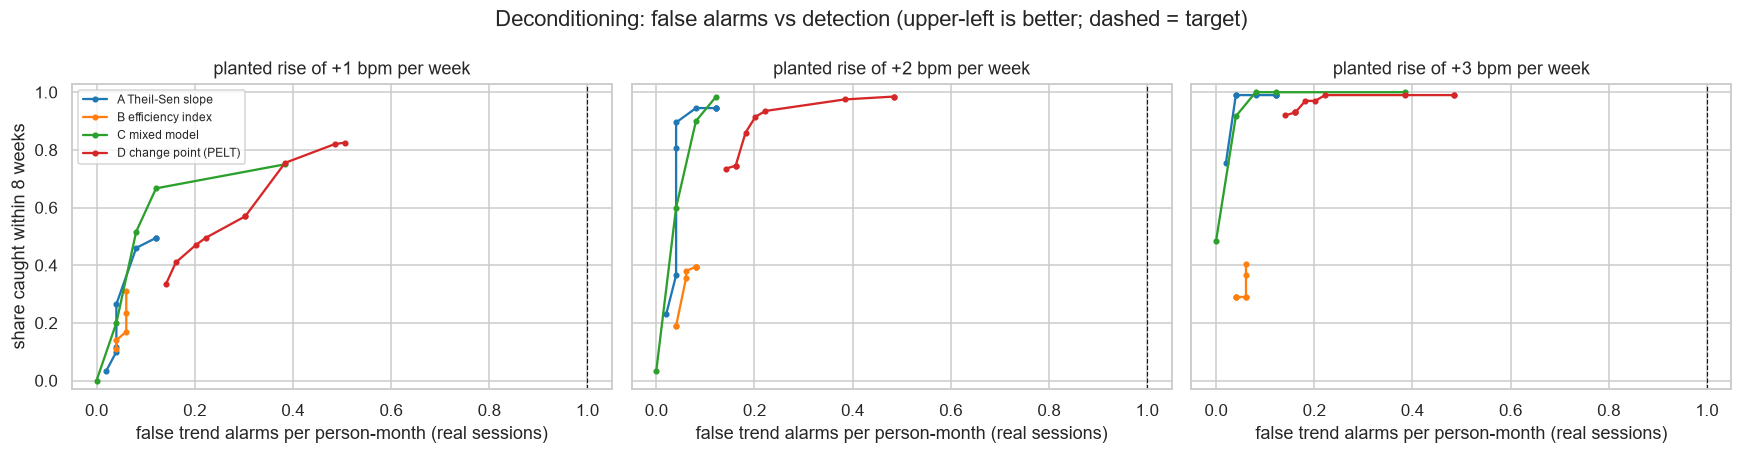

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
palette = dict(zip(sorted(res.model.unique()), sns.color_palette("tab10", 4)))
for ax, rate in zip(axes, RATES):
    for model, g in res.groupby("model"):
        g = g.sort_values("false_alarms")
        f = g[g[f"+{rate:g}_caught"] >= g[f"+{rate:g}_caught"].cummax()]
        ax.plot(f.false_alarms, f[f"+{rate:g}_caught"], marker="o", ms=3, color=palette[model], label=model)
    ax.axvline(TARGET_FA, color="k", ls="--", lw=0.8)
    ax.set(title=f"planted rise of +{rate:g} bpm per week", xlabel="false trend alarms per person-month (real sessions)", ylim=(-0.03, 1.03))
axes[0].set_ylabel("share caught within 8 weeks")
axes[0].legend(fontsize=8)
fig.suptitle("Deconditioning: false alarms vs detection (upper-left is better; dashed = target)")
savefig("03_tradeoff");

In [10]:
# Stricter operating points: a trend alarm is a slow, non-urgent message, so fewer false alarms may be worth a longer wait.
rows = []
for budget in (1.0, 0.5, 0.25, 0.1):
    for model, g in res.groupby("model"):
        ok = g[g.false_alarms <= budget]
        if len(ok):
            b = ok.sort_values(["mean_caught", "false_alarms"], ascending=[False, True]).iloc[0]
            rows.append({"budget": budget, "model": model, "setting": setting(b), "false_alarms": b.false_alarms,
                         **{f"+{r:g}": f"{b[f'+{r:g}_caught']:.0%} / {b[f'+{r:g}_weeks']:.0f} wk" for r in RATES}})
by_budget = pd.DataFrame(rows).set_index(["budget", "model"]).round(2)
by_budget

setting  false_alarms          +1          +2           +3
budget model                                                                                         
1.00   A Theil-Sen slope      lookback=8, thr=0.25          0.12  50% / 5 wk  94% / 5 wk   99% / 4 wk
       B efficiency index        lookback=6, thr=2          0.06  31% / 5 wk  38% / 4 wk   40% / 4 wk
       C mixed model           lookback=8, thr=0.5          0.38  75% / 5 wk  97% / 4 wk  100% / 3 wk
       D change point (PELT)      penalty=2, thr=3          0.49  82% / 4 wk  98% / 3 wk   99% / 3 wk
0.50   A Theil-Sen slope      lookback=8, thr=0.25          0.12  50% / 5 wk  94% / 5 wk   99% / 4 wk
       B efficiency index        lookback=6, thr=2          0.06  31% / 5 wk  38% / 4 wk   40% / 4 wk
       C mixed model           lookback=8, thr=0.5          0.38  75% / 5 wk  97% / 4 wk  100% / 3 wk
       D change point (PELT)      penalty=2, thr=3          0.49  82% / 4 wk  98% / 3 wk   99% / 3 wk
0.25   A Theil-Sen slope      lookback=8, thr=0.25          0.12  50% / 5 wk  94% / 5 wk   99% / 4 wk
       B efficiency index        lookback=6, thr=2          0.06  31% / 5 wk  38% / 4 wk   40% / 4 wk
       C mixed model          lookback=8, thr=0.75          0.12  67% / 5 wk  98% / 5 wk  100% / 4 wk
       D change point (PELT)      penalty=2, thr=8          0.22  50% / 5 wk  94% / 5 wk   99% / 4 wk
0.10   A Theil-Sen slope         lookback=8, thr=1          0.08  46% / 5 wk  94% / 5 wk   99% / 4 wk
       B efficiency index        lookback=6, thr=2          0.06  31% / 5 wk  38% / 4 wk   40% / 4 wk
       C mixed model             lookback=8, thr=1          0.08  52% / 5 wk  90% / 5 wk  100% / 4 wk

In [11]:
chosen_row = res[res.model == best.model.iloc[0]]
chosen_row = chosen_row[chosen_row.false_alarms <= TARGET_FA].sort_values(["mean_caught", "false_alarms"], ascending=[False, True]).iloc[0]
config_path = MODELS / "engine_config.json"
config = json.loads(config_path.read_text()) if config_path.exists() else {}
config["deconditioning"] = {
    "source_notebook": "03_deconditioning",
    "model": chosen_row.model,
    "params": {k: float(chosen_row[k]) for k in ("lookback", "penalty", "thr") if k in chosen_row and pd.notna(chosen_row[k])},
    "false_alarms_per_person_month_pmdata": round(float(chosen_row.false_alarms), 3),
    "detection": {f"+{r:g}_bpm_per_week": {"caught": round(float(chosen_row[f'+{r:g}_caught']), 3),
                                          "median_weeks": float(chosen_row[f'+{r:g}_weeks'])} for r in RATES},
}
config_path.write_text(json.dumps(config, indent=2))
print(json.dumps(config["deconditioning"], indent=2))

{
  "source_notebook": "03_deconditioning",
  "model": "D change point (PELT)",
  "params": {
    "penalty": 2.0,
    "thr": 3.0
  },
  "false_alarms_per_person_month_pmdata": 0.485,
  "detection": {
    "+1_bpm_per_week": {
      "caught": 0.82,
      "median_weeks": 4.0
    },
    "+2_bpm_per_week": {
      "caught": 0.985,
      "median_weeks": 3.0
    },
    "+3_bpm_per_week": {
      "caught": 0.99,
      "median_weeks": 3.0
    }
  }
}


## Decision

**Chosen: D, change-point detection (PELT) on the weekly type-centred heart rate**, penalty = 2 noise variances, alert when the latest
change point is an upward shift of at least **3 bpm** that began within the last 4 weeks. Written to `models/engine_config.json`.
The alert sentence comes straight from the model: *"Heart rate in the same exercise types has been N bpm higher for the last K weeks."*

**Numbers** (real PMData sessions, 16 people, 49 person-months; planted rises on real sessions, missed if not caught in 8 weeks):

| model | false trend alarms / person-month | +1 bpm/week | +2 bpm/week | +3 bpm/week |
|---|---|---|---|---|
| **D change point (chosen)** | 0.49 | 82 % caught, median 4 weeks | 98 %, 3 weeks | 99 %, 3 weeks |
| C mixed model (slope ≥ 0.5) | 0.38 | 75 %, 5 weeks | 97 %, 4 weeks | 100 %, 3 weeks |
| A Theil–Sen slope (≥ 0.25, 8 weeks) | 0.12 | 50 %, 5 weeks | 94 %, 5 weeks | 99 %, 4 weeks |
| B efficiency index (runs only) | 0.06 | 31 % | 38 % | 40 % |

**Why D:** the protocol asks for the fastest setting under 1 false alarm per person-month, and D is the fastest at every rate while staying at half the target.

**Rejected, and why**
- **A, weekly median + Theil–Sen (the team's first idea):** the quietest model, and the easiest to explain, but it needs 5 weeks and misses half of the +1 bpm/week rises.
  When D is tightened to A's detection level (50 % and 94 %) it still raises more false alarms than A (0.22 vs 0.12), so D's lead comes from spending more of the false-alarm budget, not from being smarter.
  **A is the fallback** if the team prefers fewer trend alarms over an earlier warning.
- **C, linear mixed model:** nearly as good as D, but it has to refit a model on the whole crew every week, a single person's slope is hard to explain in one sentence,
  and it was evaluated on 60 planted rises instead of 200 because of its cost.
- **B, efficiency index:** only usable for sessions with a distance. Just 8 of 16 people have 20 or more such sessions, so it cannot be the crew-wide model.

**Honest limits of this data (it is sparse)**
- 2,389 usable sessions, but **57 % are auto-detected walks**; walking is the best-covered activity for 13 of 16 people. A walk is a weak fitness probe.
- Session heart rate varies by **9.4 bpm** (median SD within one person and activity type), against planted rises of 1–3 bpm per week. That is why detection takes 3–5 weeks.
- Only **70 (person, start week) pairs in 11 people** have enough exercise in the following 8 weeks, so the 200 planted rises reuse them; the percentages are less certain than they look.
- PMData people are not deconditioning, so "false alarms" here are real week-to-week training changes. In flight the direction is known (fitness falls), which should help.
- On a mission the exercise is prescribed (same ARED and treadmill protocol several times a week), which gives far better like-for-like sessions than this data. These numbers are a lower bound.